## install the packages

In [116]:
! install scikit-learn==1.6.0 streamlit==1.30.0 pandas==2.0.3 numpy==1.26.4 matplotlib==3.8.2 seaborn==0.12.3 plotly==5.17.0

'install' is not recognized as an internal or external command,
operable program or batch file.


## import the libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import streamlit as st

## EDA

In [118]:
Hotel_booking = pd.read_csv('hotel_bookings.csv')
Hotel_booking.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,80.0,2017,July,29,22,2,3,2,...,No Deposit,241.0,NaN,0,Transient,253.6,0,1,Check-Out,2017-07-27
1,City Hotel,1,136.0,2017,March,12,21,0,3,2,...,No Deposit,9.0,NaN,0,Transient,93.6,0,1,Canceled,2017-02-09
2,Resort Hotel,0,103.0,2016,February,7,9,0,2,2,...,No Deposit,332.0,NaN,0,Transient-Party,50.0,0,0,Check-Out,2016-02-11
3,City Hotel,0,76.0,2016,December,52,31,2,2,2,...,No Deposit,7.0,NaN,0,Transient,96.01,0,1,Check-Out,2017-01-04
4,City Hotel,0,280.0,2016,May,18,3,0,2,2,...,No Deposit,12.0,NaN,207,Transient-Party,99.32,0,0,Check-Out,2016-05-05


In [119]:
Hotel_booking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           250000 non-null  object 
 1   is_canceled                     250000 non-null  int64  
 2   lead_time                       248044 non-null  float64
 3   arrival_date_year               250000 non-null  int64  
 4   arrival_date_month              250000 non-null  object 
 5   arrival_date_week_number        250000 non-null  int64  
 6   arrival_date_day_of_month       250000 non-null  int64  
 7   stays_in_weekend_nights         250000 non-null  int64  
 8   stays_in_week_nights            250000 non-null  int64  
 9   adults                          250000 non-null  int64  
 10  children                        248044 non-null  float64
 11  babies                          250000 non-null  int64  
 12  meal            

In [120]:
Hotel_booking.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                           1956
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                            1956
babies                                 0
meal                                   0
country                             2939
market_segment                      1963
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              33887
company         

In [121]:
Hotel_booking.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
count,250000.000000,248044.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,248044.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,216113.000000,14120.000000,250000.000000,250000.000000,250000.000000
mean,0.372136,105.001879,2016.159644,26.917484,15.821412,0.965020,2.523324,1.852004,0.104774,0.008100,0.029972,0.085860,0.135604,0.218644,86.435698,190.801912,2.337684,0.063344,0.570520
std,0.483375,107.344031,0.707915,13.562040,8.810735,1.025706,1.921845,0.555740,0.400274,0.100849,0.170510,0.837063,1.487156,0.640019,110.861067,132.355338,17.660855,0.247232,0.790537
min,0.000000,-99.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,-4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,0.000000,0.000000
25%,0.000000,20.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,67.000000,0.000000,0.000000,0.000000
50%,0.000000,70.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,183.000000,0.000000,0.000000,0.000000
75%,1.000000,161.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,35.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,8.000000,5.000000


In [122]:
Hotel_booking['adr'] = Hotel_booking['adr'].replace('EUR ', '', regex=True)
Hotel_booking['adr'] = Hotel_booking['adr'].astype(float)

print(Hotel_booking['adr'].describe())

count    248059.000000
mean        123.894449
std         565.192597
min        -299.040000
25%          69.260000
50%          94.800000
75%         126.900000
max       19979.960000
Name: adr, dtype: float64


In [123]:
Hotel_booking = Hotel_booking[['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_year', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'adr', 'is_canceled']]
Hotel_booking.head()

,hotel,lead_time,arrival_date_month,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,customer_type,adr,is_canceled
0,Resort Hotel,80.0,July,2017,22,2,3,2,0.0,0,...,TA/TO,0,0,0,F,No Deposit,241.0,Transient,253.60,0
1,City Hotel,136.0,March,2017,21,0,3,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,9.0,Transient,93.60,1
2,Resort Hotel,103.0,February,2016,9,0,2,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,332.0,Transient-Party,50.00,0
3,City Hotel,76.0,December,2016,31,2,2,2,0.0,0,...,TA/TO,0,0,0,D,No Deposit,7.0,Transient,96.01,0
4,City Hotel,280.0,May,2016,3,0,2,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,12.0,Transient-Party,99.32,0


In [124]:
Hotel_new = Hotel_booking.copy()

## Clean data

In [125]:
Hotel_new.isna().sum()

hotel                                 0
lead_time                          1956
arrival_date_month                    0
arrival_date_year                     0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                           1956
babies                                0
meal                                  0
country                            2939
market_segment                     1963
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
deposit_type                          0
agent                             33887
customer_type                         0
adr                                1941
is_canceled                           0
dtype: int64

In [126]:
Hotel_new['lead_time'].fillna(Hotel_new['lead_time'].median(), inplace=True)

Hotel_new['children'].fillna(Hotel_new['children'].mode()[0], inplace=True)

Hotel_new['country'].fillna('Unknown', inplace=True)

Hotel_new['market_segment'].fillna('Unknown', inplace=True)

Hotel_new['agent'].astype('string').fillna('null', inplace=True)

Hotel_new['adr'].fillna(Hotel_new['adr'].median(), inplace=True)


C:\Users\rawan\AppData\Local\Temp\ipykernel_33752\1476364365.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



C:\Users\rawan\AppData\Local\Temp\ipykernel_33752\1476364365.py:3: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=

In [127]:
Hotel_new.isna().sum()

hotel                                 0
lead_time                             0
arrival_date_month                    0
arrival_date_year                     0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              0
babies                                0
meal                                  0
country                               0
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
deposit_type                          0
agent                             33887
customer_type                         0
adr                                   0
is_canceled                           0
dtype: int64

In [128]:
Hotel_new['agent'] = Hotel_new['agent'].astype('string').fillna('Unknown')

print(Hotel_new['agent'].isna().sum())

0


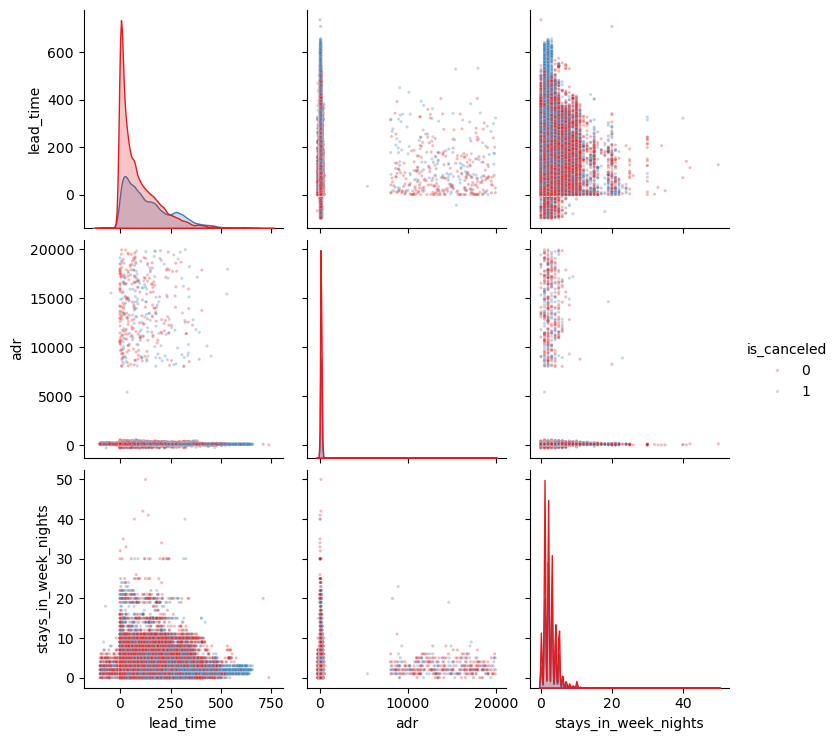

In [129]:
sns.pairplot(
    Hotel_new,
    vars=['lead_time', 'adr', 'stays_in_week_nights'],
    hue='is_canceled',
    palette='Set1',
    plot_kws={'s': 5, 'alpha': 0.3}
)

<Axes: xlabel='hotel', ylabel='count'>

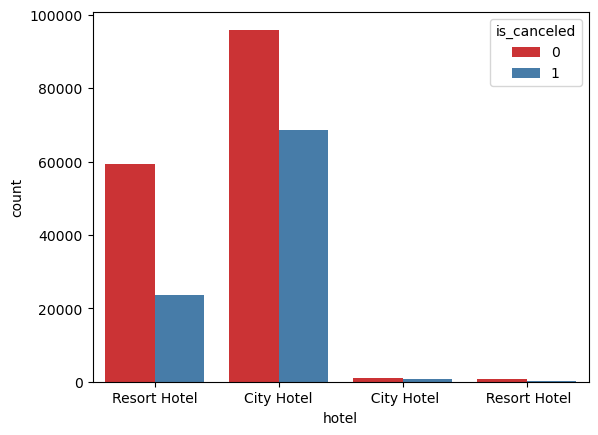

In [130]:
sns.countplot(x='hotel', hue='is_canceled', data=Hotel_new, palette='Set1')

<Axes: xlabel='customer_type', ylabel='count'>

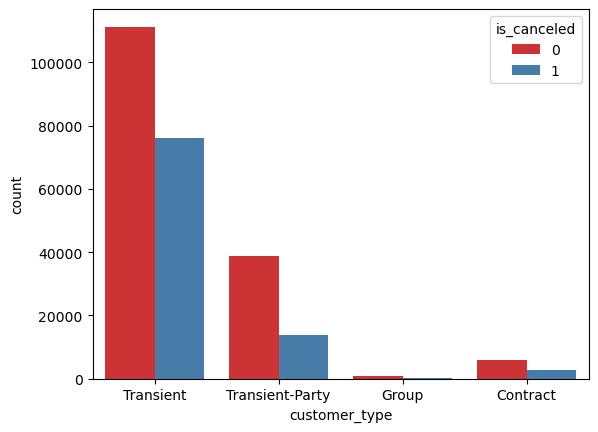

In [131]:
sns.countplot( x='customer_type', hue='is_canceled', data=Hotel_new, palette='Set1')

In [132]:
px.histogram(Hotel_new, x='arrival_date_month', y='adr', color='is_canceled', histfunc='avg', marginal='box', barmode='group', title='Average Daily Rate by Month and Cancellation Status')

## Split Input & Output

In [133]:
X = Hotel_new.drop('is_canceled', axis=1)
y = Hotel_new['is_canceled']

In [134]:
X['market_segment'].value_counts()

market_segment
Online TA        117617
Offline TA/TO     50058
Groups            41335
Direct            26065
Corporate         10962
Unknown            1963
Complementary      1505
Aviation            490
Undefined             5
Name: count, dtype: int64

In [135]:
X = pd.get_dummies(X, columns=['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type'], drop_first=True)

## Split data into Train & Test

In [136]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Apply Scaling

In [137]:
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

In [140]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)
y_pred = lr.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, lr.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.75      0.92      0.83    125656
           1       0.78      0.47      0.59     74344

    accuracy                           0.75    200000
   macro avg       0.76      0.70      0.71    200000
weighted avg       0.76      0.75      0.74    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.75      0.92      0.83     31310
           1       0.79      0.47      0.59     18690

    accuracy                           0.76     50000
   macro avg       0.77      0.70      0.71     50000
weighted avg       0.76      0.76      0.74     50000



In [141]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
y_pred = knn.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, knn.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

c:\Users\rawan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning:

Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.

  File "c:\Users\rawan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\rawan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\rawan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

classification report training:
               precision    recall  f1-score   support

           0       0.83      0.90      0.87    125656
           1       0.81      0.70      0.75     74344

    accuracy                           0.83    200000
   macro avg       0.82      0.80      0.81    200000
weighted avg       0.82      0.83      0.82    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.78      0.84      0.81     31310
           1       0.69      0.60      0.64     18690

    accuracy                           0.75     50000
   macro avg       0.73      0.72      0.73     50000
weighted avg       0.75      0.75      0.75     50000



In [142]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(x_train_scaled, y_train)
y_pred = dt.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    125656
           1       1.00      0.99      1.00     74344

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.79      0.78      0.79     31310
           1       0.64      0.65      0.65     18690

    accuracy                           0.73     50000
   macro avg       0.72      0.72      0.72     50000
weighted avg       0.73      0.73      0.73     50000



In [144]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(x_train_scaled, y_train)
y_pred = rf.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, rf.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    125656
           1       1.00      1.00      1.00     74344

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.79      0.89      0.84     31310
           1       0.76      0.61      0.68     18690

    accuracy                           0.78     50000
   macro avg       0.78      0.75      0.76     50000
weighted avg       0.78      0.78      0.78     50000



## Cross Validation

In [150]:
from sklearn.model_selection import KFold, cross_validate
Kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_validate(rf, x_train_scaled, y_train, cv=Kfold, return_train_score=True)
scores

{'fit_time': array([81.50995922, 82.39629173, 80.17782664, 75.95833397, 80.37133408,
        79.39026666, 76.49009156, 82.4985981 , 82.27096272, 86.73331428]),
 'score_time': array([1.05609584, 1.12773538, 1.0247941 , 0.98364949, 1.12116671,
        1.15906787, 1.14373922, 1.11762857, 1.06197619, 1.07491183]),
 'test_score': array([0.7835 , 0.7784 , 0.7825 , 0.7782 , 0.77735, 0.78755, 0.7783 ,
        0.78165, 0.78215, 0.78115]),
 'train_score': array([0.9974    , 0.99739444, 0.99745556, 0.99732778, 0.99735   ,
        0.99732222, 0.99738333, 0.99731667, 0.99742222, 0.99737778])}

## Hyper parameter tuning (Random Forest)


In [160]:
from sklearn.model_selection import GridSearchCV 

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [7, 15, 25, None],
    
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [7, 15, 25, None],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')

In [161]:
grid_search.best_params_

{'max_depth': None, 'n_estimators': 200}

In [162]:
rf = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42)
rf.fit(x_train_scaled, y_train)
y_pred = rf.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, rf.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    125656
           1       1.00      1.00      1.00     74344

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.79      0.89      0.84     31310
           1       0.76      0.61      0.67     18690

    accuracy                           0.78     50000
   macro avg       0.78      0.75      0.76     50000
weighted avg       0.78      0.78      0.78     50000



## Hyper parameter tuning (K-Nearest Neighbors Classifier)


In [201]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [3, 5, 7, 9],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [202]:
grid_search.best_params_

{'n_neighbors': 9, 'weights': 'distance'}

In [203]:
knn = KNeighborsClassifier(n_neighbors=9, weights='distance')
knn.fit(x_train_scaled, y_train)

y_pred = knn.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, knn.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    125656
           1       1.00      1.00      1.00     74344

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.79      0.84      0.82     31310
           1       0.70      0.62      0.66     18690

    accuracy                           0.76     50000
   macro avg       0.75      0.73      0.74     50000
weighted avg       0.76      0.76      0.76     50000



## Hyper parameter tuning (Logistic Regression Classifier)

In [204]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs']
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000, random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs']},
             scoring='accuracy')

In [206]:
grid_search.best_params_

{'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5}

In [207]:
dt = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=1,
    min_samples_split=5,
    random_state=42
)

dt.fit(x_train_scaled, y_train)
y_pred = dt.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.78      0.94      0.85    125656
           1       0.84      0.55      0.67     74344

    accuracy                           0.80    200000
   macro avg       0.81      0.75      0.76    200000
weighted avg       0.80      0.80      0.78    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.76      0.92      0.83     31310
           1       0.79      0.52      0.63     18690

    accuracy                           0.77     50000
   macro avg       0.78      0.72      0.73     50000
weighted avg       0.77      0.77      0.76     50000



## Hyper parameter tuning (DecisionTree Classifier)


In [205]:
param_grid = {
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [5, 10, 15, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [208]:
grid_search.best_params_

{'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5}

In [209]:
dt = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=1,
    min_samples_split=5,
    random_state=42
)

dt.fit(x_train_scaled, y_train)
y_pred = dt.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.78      0.94      0.85    125656
           1       0.84      0.55      0.67     74344

    accuracy                           0.80    200000
   macro avg       0.81      0.75      0.76    200000
weighted avg       0.80      0.80      0.78    200000

classification report testing:
               precision    recall  f1-score   support

           0       0.76      0.92      0.83     31310
           1       0.79      0.52      0.63     18690

    accuracy                           0.77     50000
   macro avg       0.78      0.72      0.73     50000
weighted avg       0.77      0.77      0.76     50000



In [211]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

models = {
    'Logistic Regression': lr,
    'KNN': knn,
    'Decision Tree': dt,
    'Random Forest': rf
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

comparison = []

for name, model in models.items():
    print("Evaluating:", name)

    scores = cross_validate(
        model,
        x_train_scaled,
        y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1']
    )

    comparison.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean()
    })

comparison = pd.DataFrame(comparison)
print(comparison.round(4))

Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: Decision Tree
Evaluating: Random Forest
                 Model  Accuracy  Precision  Recall      F1
0  Logistic Regression    0.7528     0.7786  0.4683  0.5848
1                  KNN    0.7566     0.6968  0.6111  0.6512
2        Decision Tree    0.7663     0.7728  0.5262  0.6260
3        Random Forest    0.7793     0.7562  0.5997  0.6689


## Create pipline for deployment

In [163]:
Hotel_booking

,hotel,lead_time,arrival_date_month,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,customer_type,adr,is_canceled
0,Resort Hotel,80.0,July,2017,22,2,3,2,0.0,0,...,TA/TO,0,0,0,F,No Deposit,241.0,Transient,253.60,0
1,City Hotel,136.0,March,2017,21,0,3,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,9.0,Transient,93.60,1
2,Resort Hotel,103.0,February,2016,9,0,2,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,332.0,Transient-Party,50.00,0
3,City Hotel,76.0,December,2016,31,2,2,2,0.0,0,...,TA/TO,0,0,0,D,No Deposit,7.0,Transient,96.01,0
4,City Hotel,280.0,May,2016,3,0,2,2,0.0,0,...,TA/TO,0,0,0,A,No Deposit,12.0,Transient-Party,99.32,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,City Hotel,331.0,July,2017,11,2,4,3,0.0,0,...,TA/TO,0,0,0,D,No Deposit,9.0,Transient,123.55,1
249996,City Hotel,74.0,December,2016,27,0,3,3,0.0,0,...,TA/TO,0,0,0,A,No Deposit,22.0,Transient,92.65,0
249997,City Hotel,393.0,March,2016,26,3,1,2,0.0,0,...,TA/TO,0,0,0,A,Non Refund,1.0,Transient,56.54,1
249998,City Hotel,132.0,September,2016,26,0,2,2,0.0,0,...,TA/TO,0,0,0,D,No Deposit,9.0,Transient,129.32,1


In [164]:
Hotel_booking.isna().sum()

hotel                                 0
lead_time                          1956
arrival_date_month                    0
arrival_date_year                     0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                           1956
babies                                0
meal                                  0
country                            2939
market_segment                     1963
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
deposit_type                          0
agent                             33887
customer_type                         0
adr                                1941
is_canceled                           0
dtype: int64

## Split insput and output


In [165]:
X = Hotel_booking.drop('is_canceled', axis=1)
y = Hotel_booking['is_canceled']

In [166]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [167]:
numerical_columns = x_train.select_dtypes(include=['int64', 'float64']).columns
numerical_columns

Index(['lead_time', 'arrival_date_year', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'agent', 'adr'],
      dtype='object')

In [168]:
categorical_columns = x_train.select_dtypes(include=['object', 'category']).columns
categorical_columns

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'deposit_type',
       'customer_type'],
      dtype='object')

In [ ]:
for columns in [
    'hotel', 'arrival_date_month', 'meal', 'country',
    'market_segment', 'distribution_channel',
    'reserved_room_type', 'deposit_type', 'customer_type'
]:
    print(columns)
    print(Hotel_new[columns].unique())
    print()

hotel
['Resort Hotel' 'City Hotel' '  City Hotel ' '  Resort Hotel ']

arrival_date_month
['July' 'March' 'February' 'December' 'May' 'June' 'August' 'September'
 'October' 'November' 'April' 'January']

meal
['HB' 'BB' 'SC' 'FB' 'bb' 'Undefined' 'undefined' 'hb' 'sc' 'fb']

country
['CN' 'AUT' 'FRA' 'PRT' 'NZL' 'USA' 'DEU' 'NLD' 'GBR' 'IRL' 'ESP' 'CHE'
 'AGO' 'Unknown' 'POL' 'ITA' 'MAR' 'BEL' 'BRA' 'KOR' 'CHN' 'TWN' 'HUN'
 'DNK' 'RUS' 'NGA' 'ROU' 'AUS' 'OMN' 'FIN' 'SWE' 'THA' 'ISR' 'CUB' 'TUR'
 'MDV' 'JPN' 'SVN' 'IND' 'MEX' 'GIB' 'CZE' 'ASM' 'BGR' 'GEO' 'LUX' 'NOR'
 'SAU' 'DZA' 'HRV' 'QAT' 'UKR' 'URY' 'CYP' 'SVK' 'GRC' 'CHL' 'MYS' 'LTU'
 'TUN' 'LVA' 'CMR' 'MOZ' 'ARG' 'SRB' 'JOR' 'EST' 'VNM' 'PRI' 'TGO' 'IRQ'
 'KAZ' 'ZAF' 'SEN' 'PER' 'PRY' 'STP' 'AZE' 'KWT' 'PHL' 'ARM' 'RWA' 'IRN'
 'SGP' 'BLR' 'PAK' 'HKG' 'AND' 'MUS' 'JEY' 'CAF' 'COL' 'MAC' 'ISL' 'NPL'
 'LKA' 'ARE' 'BHR' 'ZMB' 'GTM' 'CPV' 'ALB' 'EGY' 'LBN' 'LIE' 'VEN' 'TJK'
 'KNA' 'GGY' 'GNB' 'BGD' 'CIV' 'FRO' 'MWI' 'JAM' 'IDN' 'KHM' '

In [171]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])

numerical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler(with_mean=False))])

In [181]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'
    ))
])

categorical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot',
                 OneHotEncoder(drop='first', handle_unknown='ignore'))])

In [182]:
from sklearn.compose import ColumnTransformer 

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_columns),
        ('cat', categorical_pipeline, categorical_columns)
    ], remainder='passthrough' #Ensure that any remaining columns are passed through without any transformation
)


In [183]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 Index(['lead_time', 'arrival_date_year', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancel...
       'previous_bookings_not_canceled', 'agent', 'adr'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'))]),
                                 Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'deposit_type',
       'customer_type'],
      dtype='object'))])

In [184]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(random_state=42,n_estimators=200, max_depth=None))
])
final_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['lead_time', 'arrival_date_year', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'deposit_type',
       'customer_type'],
      dtype='object'))])),
                ('rf',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [185]:
x_train

,hotel,lead_time,arrival_date_month,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,customer_type,adr
75381,City Hotel,102.0,May,2016,7,2,3,2,0.0,0,...,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,Transient,131.39
65569,City Hotel,67.0,April,2016,5,0,3,3,0.0,0,...,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,Transient,123.00
163473,City Hotel,416.0,October,2016,4,1,2,2,0.0,0,...,Offline TA/TO,TA/TO,0,0,0,A,No Deposit,132.0,Transient-Party,124.43
90518,Resort Hotel,2.0,May,2016,10,0,1,2,0.0,0,...,Direct,Direct,0,0,0,A,No Deposit,NaN,Transient,65.41
138866,Resort Hotel,33.0,January,2017,28,0,1,2,0.0,0,...,Online TA,TA/TO,0,0,0,A,No Deposit,240.0,Transient,48.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,Resort Hotel,1.0,July,2015,17,0,2,2,0.0,0,...,Direct,Direct,0,0,0,D,No Deposit,250.0,Transient,144.50
103694,City Hotel,566.0,January,2017,26,0,2,2,0.0,0,...,Groups,TA/TO,0,0,0,A,Non Refund,1.0,Transient,62.00
131932,City Hotel,251.0,March,2016,22,0,3,1,0.0,0,...,Groups,TA/TO,0,0,0,A,Non Refund,29.0,Transient,90.00
146867,City Hotel,100.0,May,2016,19,1,3,3,0.0,0,...,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,Transient-Party,136.00


In [186]:
final_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['lead_time', 'arrival_date_year', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'deposit_type',
       'customer_type'],
      dtype='object'))])),
                ('rf',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [187]:
y_pred = final_pipeline.predict(x_test)
y_pred

c:\Users\rawan\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning:

Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros



array([0, 0, 1, ..., 0, 1, 0])

In [188]:
import joblib
joblib.dump(final_pipeline, 'hotel_booking_model.pkl')

['hotel_booking_model.pkl']

In [196]:
classifier = joblib.load('hotel_booking_model.pkl')

In [ ]:
classifier.predict(pd.DataFrame({
    'hotel': ['Resort Hotel'],
    'lead_time': [10],
    'arrival_date_month': ['July'],
    'arrival_date_year': [2017],
    'arrival_date_day_of_month': [15],
    'stays_in_weekend_nights': [2],
    'stays_in_week_nights': [5],
    'adults': [2],
    'children': [0],
    'babies': [0],
    'meal': ['BB'],
    'country': ['USA'],
    'market_segment': ['Online TA'],
    'distribution_channel': ['TA/TO'],
    'is_repeated_guest': [0],
    'previous_cancellations': [0],
    'previous_bookings_not_canceled': [1],
    'reserved_room_type': ['A'],
    'deposit_type': ['No Deposit'],
    'agent': [9],
    'customer_type': ['Transient'],
    'adr': [100.0]
}))

array([0])

In [216]:
import sys
import sklearn

print(sys.executable)
print(sklearn.__version__)

c:\Users\rawan\anaconda3\python.exe
1.6.1


In [4]:
%%writefile application.py

import calendar
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


# Set the page title and layout.
st.set_page_config(
    page_title="StayWise | Hotel Booking Prediction",
    page_icon="🏨",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

FEATURES = [
    "hotel",
    "lead_time",
    "arrival_date_month",
    "arrival_date_year",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "customer_type",
    "adr"
]

MONTHS = list(calendar.month_name)[1:]


# Set the colors and appearance.
st.markdown(
    """
    <style>
        .stApp {
            background: #f5f7fb;
            color: #17233b;
        }

        .block-container {
            padding-top: 5rem;
            padding-bottom: 3rem;
            max-width: 1350px;
        }

        [data-testid="stSidebar"] {
            background: #101d32;
        }

        [data-testid="stSidebar"] h2,
        [data-testid="stSidebar"] p,
        [data-testid="stSidebar"] label,
        [data-testid="stSidebar"] small,
        [data-testid="stSidebar"] .stMarkdown {
            color: #f3f6fc;
        }

        .hero {
            background: linear-gradient(
                120deg, #101d32, #234565
            );
            padding: 32px;
            border-radius: 18px;
            margin-bottom: 24px;
        }

        .hero-label {
            color: #83dfcf;
            font-size: 12px;
            letter-spacing: 3px;
            font-weight: 700;
        }

        .hero h1 {
            color: white;
            font-size: 36px;
            margin: 10px 0;
        }

        .hero p {
            color: #d0dbea;
            margin-bottom: 0;
        }

        [data-testid="stMetric"] {
            background: white;
            border: 1px solid #e3e8f0;
            border-radius: 14px;
            padding: 18px;
        }

        [data-testid="stMetricLabel"],
        [data-testid="stMetricValue"] {
            color: #17233b;
        }

        div[data-testid="stForm"] {
            background: white;
            border: 1px solid #e3e8f0;
            border-radius: 16px;
            padding: 24px;
        }

        .stButton button,
        .stFormSubmitButton button {
            border-radius: 10px;
            font-weight: 600;
        }

        .model-ready {
            background: #123c3d;
            color: #d9fff3;
            border-radius: 12px;
            padding: 15px;
        }

        .model-missing {
            background: #54411d;
            color: #fff1c9;
            border-radius: 12px;
            padding: 15px;
        }

        .footer {
            color: #728098;
            text-align: center;
            font-size: 12px;
            margin-top: 40px;
        }
    </style>
    """,
    unsafe_allow_html=True
)


def show_heading(label, title, description):
    st.markdown(
        f"""
        <div class="hero">
            <div class="hero-label">{label}</div>
            <h1>{title}</h1>
            <p>{description}</p>
        </div>
        """,
        unsafe_allow_html=True
    )


def format_chart(fig):
    fig.update_layout(
        template="plotly_white",
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        font=dict(color="#17233b"),
        margin=dict(l=15, r=15, t=40, b=15),
        legend_title_text=""
    )
    return fig


# Load the saved pipeline.
@st.cache_resource
def load_model(path, modified_time):
    return joblib.load(path)


classifier = None
model_error = None

model_path = BASE_DIR / "hotel_booking_model.pkl"

if model_path.exists():
    try:
        classifier = load_model(
            str(model_path),
            model_path.stat().st_mtime_ns
        )
    except Exception as error:
        model_error = str(error)


# Load the existing CSV for the dashboard.
@st.cache_data
def load_history(path, modified_time):
    df = pd.read_csv(
        path,
        na_values=["null"],
        low_memory=False
    )

    if "hotel" in df.columns:
        df["hotel"] = (
            df["hotel"].astype("string").str.strip()
        )

    if "arrival_date_month" in df.columns:
        df["arrival_date_month"] = (
            df["arrival_date_month"]
            .astype("string")
            .str.strip()
            .str.title()
        )

    if "customer_type" in df.columns:
        df["customer_type"] = (
            df["customer_type"]
            .astype("string")
            .str.strip()
        )

    if "adr" in df.columns:
        df["adr"] = pd.to_numeric(
            df["adr"].astype("string")
                     .str.replace("EUR ", "", regex=False)
                     .str.strip(),
            errors="coerce"
        )

    if "is_canceled" in df.columns:
        df["is_canceled"] = pd.to_numeric(
            df["is_canceled"],
            errors="coerce"
        )

    return df


# Match the agent input to the saved pipeline.
def prepare_agent(value, model):
    text = value.strip()

    if text:
        try:
            number = float(text)
        except ValueError:
            raise ValueError(
                "Enter a valid agent number, or leave it blank."
            )

        if (
            not np.isfinite(number)
            or number < 0
            or number % 1 != 0
        ):
            raise ValueError(
                "The agent ID must be a nonnegative whole number."
            )
    else:
        number = np.nan

    # Check whether the pipeline encodes agent as a category.
    for step in getattr(model, "named_steps", {}).values():
        if not isinstance(step, ColumnTransformer):
            continue

        for _, transformer, columns in step.transformers_:
            if not isinstance(
                columns,
                (list, tuple, pd.Index, np.ndarray)
            ):
                continue

            if "agent" not in columns:
                continue

            position = list(columns).index("agent")

            parts = [transformer]
            parts += list(
                getattr(
                    transformer, "named_steps", {}
                ).values()
            )

            for part in parts:
                if not isinstance(part, OneHotEncoder):
                    continue

                categories = part.categories_[position]

                if not text:
                    for category in categories:
                        if str(category).lower() == "unknown":
                            return category

                    return np.nan

                for category in categories:
                    try:
                        if float(category) == number:
                            return category
                    except (TypeError, ValueError):
                        pass

                if (
                    len(categories) > 0
                    and isinstance(categories[0], str)
                ):
                    return str(int(number))

    return number


def check_model():
    if classifier is not None:
        return True

    if model_error:
        st.error(
            "The model could not be opened. "
            "Check that the app uses the same Python environment "
            "as your training notebook."
        )

        with st.expander("Show error details"):
            st.code(model_error)
    else:
        st.error(
            "Place hotel_booking_model.pkl "
            "in the same folder as this app."
        )

    return False


# Add the menu and follow-up setting.
with st.sidebar:
    st.markdown("## 🏨 StayWise")
    st.caption("HOTEL BOOKING PREDICTION")

    st.divider()

    page = st.radio(
        "Choose a page",
        [
            "Overview",
            "Predict a Booking",
            "About the Model"
        ]
    )

    st.divider()

    threshold = st.slider(
        "When should a booking need follow-up?",
        min_value=10,
        max_value=90,
        value=50,
        step=5,
        format="%d%%"
    )

    st.caption(
        f"Bookings with an estimated cancellation probability "
        f"of {threshold}% or more are flagged for follow-up."
    )

    st.caption(
        "Lower this value to flag more bookings. "
        "Raise it to flag fewer bookings."
    )

    st.divider()

    if classifier is not None:
        st.markdown(
            '<div class="model-ready">'
            '✓ Model ready for predictions'
            '</div>',
            unsafe_allow_html=True
        )
    else:
        st.markdown(
            '<div class="model-missing">'
            'Model is not ready'
            '</div>',
            unsafe_allow_html=True
        )


# =========================================================
# OVERVIEW
# =========================================================

if page == "Overview":

    show_heading(
    "BOOKING OVERVIEW",
    "Understand your hotel bookings.",
    "Explore booking patterns and cancellation rates."
)

    csv_path = None

    for filename in [
        "hotel_bookings.csv",
        "hotel_bookings_250000_messy.csv"
    ]:
        candidate = BASE_DIR / filename

        if candidate.exists():
            csv_path = candidate
            break

    if csv_path is None:
        st.info(
            "To display the dashboard, place hotel_bookings.csv "
            "in the same folder as this app."
        )

        st.write(
            "You can still use Predict a Booking "
            "without the dashboard CSV."
        )

    else:
        try:
            df = load_history(
                str(csv_path),
                csv_path.stat().st_mtime_ns
            )

            required = [
                "hotel",
                "arrival_date_month",
                "customer_type",
                "adr",
                "is_canceled"
            ]

            missing = [
                column for column in required
                if column not in df.columns
            ]

            if missing:
                st.error(
                    "The dashboard CSV is missing: "
                    + ", ".join(missing)
                )

            else:
                first, second, third = st.columns(3)

                with first:
                    hotels = st.multiselect(
                        "Hotel",
                        sorted(
                            df["hotel"]
                            .dropna()
                            .unique()
                            .tolist()
                        )
                    )

                with second:
                    months = st.multiselect(
                        "Arrival month",
                        MONTHS
                    )

                with third:
                    customers = st.multiselect(
                        "Customer type",
                        sorted(
                            df["customer_type"]
                            .dropna()
                            .unique()
                            .tolist()
                        )
                    )

                filtered = df.copy()

                if hotels:
                    filtered = filtered[
                        filtered["hotel"].isin(hotels)
                    ]

                if months:
                    filtered = filtered[
                        filtered["arrival_date_month"].isin(
                            months
                        )
                    ]

                if customers:
                    filtered = filtered[
                        filtered["customer_type"].isin(
                            customers
                        )
                    ]

                if filtered.empty:
                    st.info(
                        "No bookings match your selected filters."
                    )

                else:
                    outcomes = filtered[
                        filtered["is_canceled"].isin([0, 1])
                    ].copy()

                    rates = filtered.loc[
                        filtered["adr"] >= 0,
                        "adr"
                    ]

                    first, second, third, fourth = st.columns(4)

                    first.metric(
                        "Total bookings",
                        f"{len(filtered):,}"
                    )

                    second.metric(
                        "Canceled bookings",
                        f"{int(outcomes['is_canceled'].sum()):,}"
                    )

                    rate = outcomes["is_canceled"].mean()

                    third.metric(
                        "Cancellation rate",
                        (
                            f"{rate:.1%}"
                            if pd.notna(rate)
                            else "Unavailable"
                        )
                    )

                    fourth.metric(
                        "Average nightly rate",
                        (
                            f"{rates.mean():,.2f}"
                            if not rates.empty
                            else "Unavailable"
                        )
                    )

                    st.caption(
                        "These figures summarize your saved CSV. "
                        "Missing and negative room rates are excluded "
                        "from the average nightly rate."
                    )

                    left, right = st.columns(2)

                    with left:
                        st.subheader(
                            "Cancellation rate by month"
                        )

                        monthly = (
                            outcomes.groupby(
                                "arrival_date_month",
                                as_index=False
                            )["is_canceled"].mean()
                        )

                        monthly["Cancellation rate (%)"] = (
                            monthly["is_canceled"] * 100
                        )

                        fig = px.bar(
                            monthly,
                            x="arrival_date_month",
                            y="Cancellation rate (%)",
                            category_orders={
                                "arrival_date_month": MONTHS
                            },
                            color_discrete_sequence=[
                                "#14b8a6"
                            ],
                            labels={
                                "arrival_date_month":
                                "Arrival month"
                            }
                        )

                        st.plotly_chart(
                            format_chart(fig),
                            use_container_width=True
                        )

                    with right:
                        st.subheader(
                            "Booking outcomes by hotel"
                        )

                        counts = (
                            outcomes.groupby(
                                ["hotel", "is_canceled"]
                            )
                            .size()
                            .reset_index(name="Bookings")
                        )

                        counts["Outcome"] = (
                            counts["is_canceled"].map({
                                0: "Not Canceled",
                                1: "Canceled"
                            })
                        )

                        fig = px.bar(
                            counts,
                            x="hotel",
                            y="Bookings",
                            color="Outcome",
                            barmode="group",
                            color_discrete_map={
                                "Not Canceled": "#14b8a6",
                                "Canceled": "#f97373"
                            },
                            labels={"hotel": "Hotel"}
                        )

                        st.plotly_chart(
                            format_chart(fig),
                            use_container_width=True
                        )

                    valid_rates = filtered[
                        filtered["adr"].ge(0)
                    ]

                    monthly_rates = (
                        valid_rates.groupby(
                            ["arrival_date_month", "hotel"],
                            as_index=False
                        )["adr"].mean()
                    )

                    fig = px.line(
                        monthly_rates,
                        x="arrival_date_month",
                        y="adr",
                        color="hotel",
                        markers=True,
                        category_orders={
                            "arrival_date_month": MONTHS
                        },
                        labels={
                            "arrival_date_month": "Arrival month",
                            "adr": "Average nightly rate",
                            "hotel": "Hotel"
                        }
                    )

                    

        except Exception as error:
            st.error(
                "The dashboard could not be displayed."
            )

            with st.expander("Show error details"):
                st.code(str(error))


# =========================================================
# PREDICT ONE BOOKING
# =========================================================

elif page == "Predict a Booking":

    show_heading(
        "BOOKING PREDICTION",
        "Check a booking's cancellation risk.",
        "Enter the reservation details to see its prediction "
        "and whether a confirmation follow-up is suggested."
    )

    with st.form("booking_form"):

        reservation_tab, guest_tab, history_tab = st.tabs([
            "Reservation details",
            "Guest details",
            "Booking history"
        ])

        with reservation_tab:
            first, second = st.columns(2)

            with first:
                hotel = st.selectbox(
                    "Hotel",
                    ["Resort Hotel", "City Hotel"]
                )

                arrival = st.date_input(
                    "Arrival date",
                    value=date(2017, 7, 15),
                    help=(
                        "The training data covers 2015–2017. "
                        "Performance on later dates has not "
                        "been established."
                    )
                )

                lead_time = st.number_input(
                    "Days between booking and arrival",
                    min_value=0,
                    value=10,
                    step=1
                )

                room = st.selectbox(
                    "Reserved room type",
                    [
                        "A", "B", "C", "D", "E",
                        "F", "G", "H", "L", "P"
                    ]
                )

            with second:
                weekend_nights = st.number_input(
                    "Weekend nights",
                    min_value=0,
                    value=2,
                    step=1
                )

                week_nights = st.number_input(
                    "Week nights",
                    min_value=0,
                    value=5,
                    step=1
                )

                adr = st.number_input(
                    "Average room price per night",
                    min_value=0.0,
                    value=100.0,
                    step=1.0
                )

                deposit = st.selectbox(
                    "Deposit type",
                    [
                        "No Deposit",
                        "Non Refund",
                        "Refundable"
                    ]
                )

        with guest_tab:
            first, second = st.columns(2)

            with first:
                adults = st.number_input(
                    "Adults",
                    min_value=0,
                    value=2,
                    step=1
                )

                children = st.number_input(
                    "Children",
                    min_value=0,
                    value=0,
                    step=1
                )

                babies = st.number_input(
                    "Babies",
                    min_value=0,
                    value=0,
                    step=1
                )

                country = st.text_input(
                    "Country code",
                    value="USA",
                    help="For example: USA, PRT or ARE."
                )

                meal = st.selectbox(
                    "Meal package",
                    ["BB", "HB", "FB", "SC", "Undefined"]
                )

            with second:
                segment = st.selectbox(
                    "Market segment",
                    [
                        "Online TA",
                        "Offline TA/TO",
                        "Direct",
                        "Corporate",
                        "Groups",
                        "Complementary",
                        "Aviation",
                        "Unknown",
                        "Undefined"
                    ]
                )

                channel = st.selectbox(
                    "Distribution channel",
                    [
                        "TA/TO",
                        "Direct",
                        "Corporate",
                        "GDS",
                        "Undefined"
                    ]
                )

                customer = st.selectbox(
                    "Customer type",
                    [
                        "Transient",
                        "Transient-Party",
                        "Contract",
                        "Group"
                    ]
                )

                agent_input = st.text_input(
                    "Agent ID",
                    value="",
                    help="Leave this blank if the agent is unknown."
                )

        with history_tab:
            repeated = st.selectbox(
                "Is this a returning guest?",
                ["No", "Yes"]
            )

            previous_cancellations = st.number_input(
                "Number of previous cancellations",
                min_value=0,
                value=0,
                step=1
            )

            previous_completed = st.number_input(
                "Previous bookings not canceled",
                min_value=0,
                value=1,
                step=1
            )

        submitted = st.form_submit_button(
            "Predict cancellation",
            type="primary"
        )

    if submitted:
        st.session_state.pop("booking_result", None)

        if adults + children + babies == 0:
            st.error(
                "Enter at least one guest."
            )

        elif weekend_nights + week_nights == 0:
            st.error(
                "Enter at least one night."
            )

        elif check_model():
            try:
                agent = prepare_agent(
                    agent_input,
                    classifier
                )

                booking = pd.DataFrame({
                    "hotel": [hotel],
                    "lead_time": [lead_time],
                    "arrival_date_month": [
                        arrival.strftime("%B")
                    ],
                    "arrival_date_year": [arrival.year],
                    "arrival_date_day_of_month": [
                        arrival.day
                    ],
                    "stays_in_weekend_nights": [
                        weekend_nights
                    ],
                    "stays_in_week_nights": [
                        week_nights
                    ],
                    "adults": [adults],
                    "children": [children],
                    "babies": [babies],
                    "meal": [meal],
                    "country": [
                        country.strip().upper()
                        if country.strip()
                        else "Unknown"
                    ],
                    "market_segment": [segment],
                    "distribution_channel": [channel],
                    "is_repeated_guest": [
                        int(repeated == "Yes")
                    ],
                    "previous_cancellations": [
                        previous_cancellations
                    ],
                    "previous_bookings_not_canceled": [
                        previous_completed
                    ],
                    "reserved_room_type": [room],
                    "deposit_type": [deposit],
                    "agent": [agent],
                    "customer_type": [customer],
                    "adr": [adr]
                })

                expected = list(
                    getattr(
                        classifier,
                        "feature_names_in_",
                        FEATURES
                    )
                )

                missing = (
                    set(expected) - set(booking.columns)
                )

                if missing:
                    raise ValueError(
                        "The saved model expects different inputs: "
                        + ", ".join(sorted(missing))
                    )

                booking = booking[expected]

                with st.spinner(
                    "Calculating the prediction..."
                ):
                    prediction = classifier.predict(
                        booking
                    )[0]

                    classes = list(
                        classifier.classes_
                    )

                    if 1 not in classes:
                        raise ValueError(
                            "The saved model must use 1 "
                            "for canceled bookings."
                        )

                    probability = (
                        classifier.predict_proba(booking)[
                            0, classes.index(1)
                        ]
                    )

                st.session_state["booking_result"] = {
                    "prediction": int(prediction),
                    "probability": float(probability),
                    "booking": booking,
                    "nights": (
                        weekend_nights + week_nights
                    ),
                    "guests": (
                        adults + children + babies
                    ),
                    "room_charges": (
                        weekend_nights + week_nights
                    ) * adr
                }

            except Exception as error:
                st.error(
                    "The prediction could not be completed."
                )

                with st.expander("Show error details"):
                    st.code(str(error))

    if "booking_result" in st.session_state:
        result = st.session_state["booking_result"]

        probability = result["probability"]
        threshold_value = threshold / 100

        st.divider()
        st.subheader("Prediction result")

        left, right = st.columns([1, 1.3])

        with left:
            gauge = go.Figure(
                go.Indicator(
                    mode="gauge+number",
                    value=probability * 100,
                    number={"suffix": "%"},
                    title={
                        "text": "Estimated cancellation probability"
                    },
                    gauge={
                        "axis": {"range": [0, 100]},
                        "bar": {"color": "#234565"},
                        "steps": [
                            {
                                "range": [0, threshold],
                                "color": "#d5f4eb"
                            },
                            {
                                "range": [threshold, 100],
                                "color": "#ffdede"
                            }
                        ],
                        "threshold": {
                            "line": {
                                "color": "#ef4444",
                                "width": 3
                            },
                            "value": threshold
                        }
                    }
                )
            )

            gauge.update_layout(height=300)

            st.plotly_chart(
                format_chart(gauge),
                use_container_width=True
            )

        with right:
            if result["prediction"] == 1:
                st.markdown(
                    "### Model prediction: likely to cancel"
                )
            else:
                st.markdown(
                    "### Model prediction: likely not to cancel"
                )

            if probability >= threshold_value:
                st.warning(
                    "A confirmation follow-up is suggested "
                    "for this booking."
                )
            else:
                st.success(
                    "This booking is not flagged for priority "
                    "follow-up. Continue with the usual "
                    "confirmation process."
                )

            st.write(
                f"Your selected follow-up threshold is "
                f"**{threshold}%**."
            )

            st.caption(
                "The threshold controls the follow-up suggestion. "
                "It does not change the model's original prediction."
            )

            st.caption(
                "The percentage is an estimate, "
                "not a guarantee that the guest will cancel."
            )

        first, second, third = st.columns(3)

        first.metric(
            "Total nights",
            result["nights"]
        )

        second.metric(
            "Total guests",
            result["guests"]
        )

        third.metric(
            "Estimated room charges",
            f"{result['room_charges']:,.2f}"
        )

        st.caption(
            "Estimated room charges = nightly rate × nights. "
            "Extras and taxes are not included."
        )

        with st.expander("View the booking details"):
            st.dataframe(
                result["booking"],
                use_container_width=True,
                hide_index=True
            )

        st.caption(
            "Showing the last submitted booking. "
            "After changing any details, "
            "click Predict cancellation again."
        )


# =========================================================
# ABOUT THE MODEL
# =========================================================

else:
    show_heading(
        "ABOUT THIS PROJECT",
        "How the prediction works.",
        "Understand the business question, "
        "model results and limitations."
    )

    st.subheader("Business question")

    st.write(
        "Which hotel bookings are likely to be canceled, "
        "so hotel staff can prioritize confirmation follow-ups "
        "and improve room availability planning?"
    )

    st.subheader("Selected model")

    st.write(
        "Random Forest was selected because it achieved "
        "the highest average accuracy and cancellation "
        "F1-score in the recorded cross-validation comparison."
    )

    comparison = pd.DataFrame({
        "Model": [
            "Logistic Regression",
            "KNN",
            "Decision Tree",
            "Random Forest"
        ],
        "Accuracy": [
            0.7528, 0.7566, 0.7663, 0.7793
        ],
        "Precision": [
            0.7786, 0.6968, 0.7728, 0.7562
        ],
        "Recall": [
            0.4683, 0.6111, 0.5262, 0.5997
        ],
        "F1": [
            0.5848, 0.6512, 0.6260, 0.6689
        ]
    })

    first, second, third = st.columns(3)

    first.metric(
        "Recorded RF validation accuracy",
        "77.93%"
    )

    second.metric(
        "Cancellation recall",
        "59.97%"
    )

    third.metric(
        "Cancellation F1-score",
        "66.89%"
    )

    st.dataframe(
        comparison.style.format({
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}"
        }),
        use_container_width=True,
        hide_index=True
    )

    st.caption(
        "These are the five-fold cross-validation results "
        "recorded in the project notebook. "
        "They are not recalculated by this app."
    )

    chart_data = comparison.melt(
        id_vars="Model",
        value_vars=["Accuracy", "Recall", "F1"],
        var_name="Metric",
        value_name="Score"
    )

    fig = px.bar(
        chart_data,
        x="Model",
        y="Score",
        color="Metric",
        barmode="group",
        color_discrete_sequence=[
            "#234565", "#14b8a6", "#e9b44c"
        ]
    )

    fig.update_yaxes(
        range=[0, 1],
        tickformat=".0%"
    )

    st.plotly_chart(
        format_chart(fig),
        use_container_width=True
    )

    with st.expander("What do the scores mean?"):
        st.markdown(
            """
            - **Accuracy:** how many bookings were classified
              correctly overall.
            - **Precision:** how many cancellation alerts
              were correct.
            - **Recall:** how many actual cancellations
              the model identified.
            - **F1-score:** a score combining precision
              and recall.
            """
        )

    with st.expander("What does the follow-up threshold do?"):
        st.write(
            "The threshold decides when the app suggests "
            "a confirmation follow-up."
        )

        st.write(
            "For example, at a 50% threshold, "
            "a booking with an estimated 70% cancellation "
            "probability is flagged for follow-up. "
            "A booking at 30% is not."
        )

        st.write(
            "Lowering the threshold flags more bookings. "
            "Raising it flags fewer bookings."
        )

    with st.expander("Project limitations"):
        st.markdown(
            """
            - The dataset contains original and synthetic bookings.
            - The model showed overfitting during evaluation.
            - Some cancellations will not be identified.
            - Probability estimates are uncertain and have
              not been verified as calibrated probabilities.
            - Historical results do not establish performance
              for future dates or new hotels.
            - A final evaluation should use original bookings
              excluded from synthetic-data generation.
            - Follow-up suggestions support staff decisions;
              the app does not contact guests automatically.
            """
        )

    with st.expander("Which information does the model use?"):
        st.dataframe(
            pd.DataFrame({
                "Input column": FEATURES
            }),
            use_container_width=True,
            hide_index=True
        )


# Add a short footer.
st.markdown(
    """
    <div class="footer">
        StayWise · Hotel Booking Prediction<br>
        Data Science for Business Applications 
    </div>
    """,
    unsafe_allow_html=True
)

Overwriting application.py


In [224]:
import sys
import sklearn

print(sys.executable)
print(sklearn.__version__)

c:\Users\rawan\anaconda3\python.exe
1.6.1
